# IoT Device Classification: JA4 + JA4S
## Random Forest vs. CatBoost vs. Dictionary Matching on UNSW-IoTraffic and CIC-IoT-2023

### HW & SW definition

In [1]:
# --- REPRODUCIBILITY, HARDWARE CAPABILITIES & SOFTWARE ENVIRONMENT REPORT ---
# Automatically extracts hardware limitations (CPU frequencies, threads, RAM), 
# OS/WSL environment, and core ML model versions (Random Forest / CatBoost) for academic reporting.
import sys
import platform
import psutil
import os
import pandas as pd
import numpy as np
import sklearn
import catboost
import statsmodels

def get_complete_environment_specs():
    specs = {}
    
    # 1. Hardware Capabilities & Limitations (CPU & RAM constraints)
    uname = platform.uname()
    specs["Machine Architecture"] = uname.machine
    specs["Processor Type"] = uname.processor if uname.processor else platform.processor()
    specs["Physical CPU Cores"] = psutil.cpu_count(logical=False)
    specs["Logical CPU Cores (Threads)"] = psutil.cpu_count(logical=True)
    
    cpu_freq = psutil.cpu_freq()
    if cpu_freq:
        specs["CPU Current Frequency"] = f"{cpu_freq.current:.2f} MHz"
        specs["CPU Max Frequency"] = f"{cpu_freq.max:.2f} MHz" if cpu_freq.max else "N/A"
        specs["CPU Min Frequency"] = f"{cpu_freq.min:.2f} MHz" if cpu_freq.min else "N/A"
        
    ram = psutil.virtual_memory()
    specs["Total System RAM"] = f"{ram.total / (1024**3):.2f} GB"
    specs["Available System RAM"] = f"{ram.available / (1024**3):.2f} GB"
    specs["Current RAM Usage"] = f"{ram.percent}%"
    
    # 2. OS & WSL / Ubuntu Details
    specs["Base OS Platform"] = platform.system()
    specs["OS Release"] = platform.release()
    specs["OS Version"] = platform.version()
    
    # Check for Linux / WSL distribution release file
    if os.path.exists("/etc/os-release"):
        try:
            with open("/etc/os-release", "r") as f:
                for line in f:
                    if line.startswith("PRETTY_NAME="):
                        specs["Linux/WSL Distribution"] = line.split("=")[1].strip().strip('"')
        except Exception:
            pass
            
    # Check kernel version to identify WSL signature
    if os.path.exists("/proc/version"):
        try:
            with open("/proc/version", "r") as f:
                kernel_info = f.read().strip()
                specs["Kernel Version"] = kernel_info
                if "microsoft" in kernel_info.lower() or "wsl" in kernel_info.lower():
                    specs["Execution Environment"] = "WSL (Windows Subsystem for Linux)"
                else:
                    specs["Execution Environment"] = "Native Linux / Bare Metal"
        except Exception:
            pass
    else:
        specs["Execution Environment"] = "Windows Native Host"
        
    # 3. Software Stack & Model Engine Versions
    specs["Python Version"] = sys.version.split()[0]
    specs["Random Forest Engine (Scikit-Learn)"] = sklearn.__version__
    specs["CatBoost Version"] = catboost.__version__
    specs["Statsmodels Version"] = statsmodels.__version__
    specs["Pandas Version"] = pd.__version__
    specs["NumPy Version"] = np.__version__
    
    return specs

full_env_metadata = get_complete_environment_specs()

print("=" * 80)
print("COMPLETE EXPERIMENTAL SETUP REPORT")
print("=" * 80)
for key, value in full_env_metadata.items():
    print(f" • {key}: {value}")
print("=" * 80)

COMPLETE EXPERIMENTAL SETUP REPORT
 • Machine Architecture: AMD64
 • Processor Type: Intel64 Family 6 Model 142 Stepping 12, GenuineIntel
 • Physical CPU Cores: 4
 • Logical CPU Cores (Threads): 8
 • CPU Current Frequency: 1803.00 MHz
 • CPU Max Frequency: 2304.00 MHz
 • CPU Min Frequency: N/A
 • Total System RAM: 15.71 GB
 • Available System RAM: 4.19 GB
 • Current RAM Usage: 73.3%
 • Base OS Platform: Windows
 • OS Release: 11
 • OS Version: 10.0.26200
 • Execution Environment: Windows Native Host
 • Python Version: 3.13.14
 • Random Forest Engine (Scikit-Learn): 1.8.0
 • CatBoost Version: 1.2.10
 • Statsmodels Version: 0.15.0
 • Pandas Version: 3.0.2
 • NumPy Version: 2.4.4


### Purpose and reviewer traceability
This notebook evaluates whether compact JA4+JA4S fingerprints or their decomposed protocol-level attributes are more useful for passive IoT device identification. The contribution is empirical rather than a new fingerprint or classifier, addressing Reviewer 1 Concern 1 and Reviewer 2 Concern 1.

The experimental design responds to the following review requirements:

1. **Independent validation (Reviewers 1 and 3, Concerns 4, 6 and 1):** the same pipeline is evaluated on UNSW-IoTraffic and CIC-IoT-2023.
2. **Classifier diversity (Reviewers 1 and 2, Concern 2; Reviewer 3, Concern 5):** Random Forest and CatBoost are compared, together with an exact dictionary baseline. This does not establish generality to every classifier family.
3. **Filtering transparency (Reviewers 2 and 3, Concern 3 and 4):** invalid fingerprints, classes with fewer than five samples, and the random cap of 500 samples per class are reported.
4. **Statistical comparison (Reviewer 1, Concern 3):** bootstrap confidence intervals, paired tests and McNemar tests are calculated on the same test observations. The interpretation remains limited to the evaluated partitions.
5. **Operational cost (Reviewers 1 and 3, Concern 8 and 2):** training time, inference latency, throughput and memory are measured.
6. **Passive scope (Reviewers 1 and 3, Concern 7 and 5):** the notebook uses observed fingerprints only; it does not inspect payloads, actively probe devices or test adversarial spoofing.

### Representation terminology
The **Full** representation uses the complete `ja4` and `ja4s` strings. The **Decomposed** representation exposes protocol, TLS, SNI, cipher, extension, ALPN and hash-related fields individually. Decomposition is therefore evaluated both for predictive performance and for feature-level interpretability, as requested by Reviewer 2 Concern 5.

### Decision criteria
For classification quality, the primary metric is macro F1:

$$
F1_c = 2 \frac{Precision_c \cdot Recall_c}{Precision_c + Recall_c},
\qquad
F1_{macro} = \frac{1}{C}\sum_{c=1}^{C}F1_c
$$

Macro averaging gives every device class the same weight. Accuracy, macro precision and macro recall are reported as complementary metrics. A method is operationally preferable only when its predictive performance is considered together with latency, throughput and memory; the highest F1 alone does not establish practical superiority.

### Scope of statistical evidence
A p-value below 0.05 is treated as evidence against equal performance for the corresponding paired comparison. When two models make exactly the same decisions, a variance-based paired t-test is undefined and McNemar has no discordant pairs; those cases are reported as degenerate comparisons rather than interpreted as significant differences.

In [2]:
import os
import time
import sys
import psutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    top_k_accuracy_score,
    classification_report,
    make_scorer,
)
from statsmodels.stats.contingency_tables import mcnemar
from scipy.stats import ttest_rel

from catboost import CatBoostClassifier

# Display all pandas floating-point values with four decimals.
pd.set_option("display.float_format", lambda value: f"{value:.4f}")

# Global configuration paths and constraints
DATASETS_CONFIG = {
    "UNSW": {
        "path": r"C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\1_Data\raw_fingerprints\unsw_raw_features.csv",
        "min_samples": 5,
        "max_samples": 500
    },
    "CIC_IOT": {
        "path": r"C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\1_Data\raw_fingerprints\cic_iot_raw_features.csv",
        "min_samples": 5,
        "max_samples": 500
    }
}

OUTPUT_DIR = r"C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\Resultados_Consolidados"
os.makedirs(OUTPUT_DIR, exist_ok=True)
EXCEL_PATH = os.path.join(OUTPUT_DIR, "Comparativa_Modelos_Avanzada_JA4_JA4S.xlsx")

## 1. Exploratory Data Analysis, Fingerprint Inspection, and Filtering Audit

**Reviewer 2, Concern 3 and Reviewer 3, Concern 4.** This section documents the number of observations and device classes before and after cleaning. It also shows the complete compact representation (`ja4`, `ja4s`) together with every decomposed feature. Classes with fewer than `min_samples=5` observations are excluded because they cannot support a stable per-device train/test split. Retained classes are randomly capped at `max_samples=500` observations using seed 42, so the cap is reproducible without always selecting the first records.

The audit also reports the proportion of repeated compact pairs:

$$
Repeated\ pairs = Valid\ samples - Unique\ (JA4, JA4S)\ pairs
$$

This matters because exact dictionary matching benefits directly from repeated pairs, whereas a model can potentially generalize from individual decomposed attributes.

In [3]:
# Reviewer 2, Concern 3 and Reviewer 3, Concern 4:
# Audit the effect of class filtering and make the retained sample support explicit.
DECOMPOSED_FEATURES = [
    "ja4_protocol", "ja4_tls_version", "ja4_sni_type", "ja4_n_ciphers",
    "ja4_n_extensions", "ja4_alpn", "ja4_cipher_hash", "ja4_extension_hash",
    "ja4s_protocol", "ja4s_tls_version", "ja4s_n_extensions", "ja4s_alpn",
    "ja4s_cipher_chosen", "ja4s_extension_hash"
]
NUMERIC_DECOMPOSED = ["ja4_n_ciphers", "ja4_n_extensions", "ja4s_n_extensions"]
CATEGORICAL_DECOMPOSED = [c for c in DECOMPOSED_FEATURES if c not in NUMERIC_DECOMPOSED]
FULL_FEATURES = ["ja4", "ja4s"]
TARGET_COL = "device_name"

def analyze_and_clean_dataset(csv_path, min_samples=5, max_samples=500, dataset_name="Dataset"):
    print("=" * 80)
    print(f"EXPLORATORY AUDIT & FILTERING ANALYSIS: {dataset_name}")
    print("=" * 80)

    # Reviewer 2, Concern 3: report the original sample and class counts.
    df_raw = pd.read_csv(csv_path, dtype=str, low_memory=False)
    init_samples = len(df_raw)
    init_classes = df_raw[TARGET_COL].nunique()

    # Reviewer 1, Concern 7 and Reviewer 3, Concern 5:
    # keep only usable passive JA4/JA4S observations; no payload or active probing is used.
    valid_mask = (
        df_raw["ja4"].notna() & df_raw["ja4"].str.strip().ne("") &
        df_raw["ja4s"].notna() & df_raw["ja4s"].str.strip().ne("") &
        ~df_raw["ja4s"].str.strip().str.lower().isin(["(empty)", "(emtpy)"])
    )
    df_valid = df_raw[valid_mask].copy()

    # Reviewer 1, Concern 1 and Reviewer 2, Concern 5:
    # quantify repeated versus unique compact JA4+JA4S representations.
    df_valid["fingerprint_pair"] = df_valid["ja4"] + " | " + df_valid["ja4s"]
    total_pairs = len(df_valid)
    unique_pairs = df_valid["fingerprint_pair"].nunique()
    repeated_pairs = total_pairs - unique_pairs

    print(f"[Fingerprint Stats] Total valid samples: {total_pairs}")
    print(f"[Fingerprint Stats] Unique JA4+JA4S pairs: {unique_pairs} ({unique_pairs/total_pairs*100:.2f}%)")
    print(f"[Fingerprint Stats] Repeated JA4+JA4S pairs: {repeated_pairs} ({repeated_pairs/total_pairs*100:.2f}%)")

    # Reviewer 2, Concern 5: show compact fingerprints and every decomposed attribute
    # side by side so that decomposition is transparent and reproducible.
    print("\n--- SAMPLE FULL & DECOMPOSED REPRESENTATION EXAMPLES ---")
    sample_columns = [TARGET_COL] + FULL_FEATURES + DECOMPOSED_FEATURES
    sample_subset = df_valid[sample_columns].head(3)
    display(sample_subset)

    # Reviewer 2, Concern 3 and Reviewer 3, Concern 4:
    # exclude classes with insufficient observations before splitting.
    dev_counts = df_valid[TARGET_COL].value_counts()
    dropped_classes = dev_counts[dev_counts < min_samples].index.tolist()
    retained_devices = dev_counts[dev_counts >= min_samples].index
    df_filtered = df_valid[df_valid[TARGET_COL].isin(retained_devices)].copy()

    # Reviewer 2, Concern 3 and Reviewer 3, Concern 4:
    # randomly cap each retained device at max_samples, using a fixed seed for reproducibility.
    if max_samples:
        rng = np.random.default_rng(42)
        df_filtered = df_filtered.assign(_random_order=rng.random(len(df_filtered)))
        df_filtered = (
            df_filtered.sort_values([TARGET_COL, "_random_order"])
            .groupby(TARGET_COL, group_keys=False)
            .head(max_samples)
            .drop(columns="_random_order")
            .reset_index(drop=True)
        )
    final_samples = len(df_filtered)
    final_classes = df_filtered[TARGET_COL].nunique()

    audit_summary = {
        "Dataset": dataset_name,
        "Initial Samples": init_samples,
        "Valid Samples (Pre-filter)": total_pairs,
        "Filtered Samples (Post-min/max)": final_samples,
        "Initial Classes": init_classes,
        "Retained Classes": final_classes,
        "Dropped Classes Count": len(dropped_classes),
        "Dropped Classes List": str(dropped_classes)
    }

    print(f"[Audit Summary] Retained Classes: {final_classes}/{init_classes} | Final Samples: {final_samples}")
    print("-" * 80)

    # Convert decomposed count fields to numeric and remove malformed numeric records.
    for c in NUMERIC_DECOMPOSED:
        df_filtered[c] = pd.to_numeric(df_filtered[c], errors='coerce')
    df_filtered = df_filtered.dropna(subset=NUMERIC_DECOMPOSED).reset_index(drop=True)

    # Normalize labels and categorical fingerprint fields for consistent encoding.
    for c in [TARGET_COL] + FULL_FEATURES + CATEGORICAL_DECOMPOSED:
        df_filtered[c] = df_filtered[c].fillna("unknown").astype(str).str.strip().str.lower()

    return df_filtered, audit_summary

def split_data_per_device(df, test_size=0.2, random_state=42):
    # Reviewer 1, Concern 3: hold out the same proportion within every device
    # so each evaluated class contributes to both training and testing.
    train_list, test_list = [], []
    for dev in df[TARGET_COL].unique():
        sub_df = df[df[TARGET_COL] == dev]
        if len(sub_df) < 2:
            train_list.append(sub_df)
            continue
        tr, ts = train_test_split(
            sub_df,
            test_size=test_size,
            random_state=random_state,
            shuffle=True
        )
        train_list.append(tr)
        test_list.append(ts)
    return pd.concat(train_list, ignore_index=True), pd.concat(test_list, ignore_index=True)

## 2. Dictionary Matching Baseline Implementation

**Reviewer 4, Concern 1.** The dictionary baseline performs exact matching between the complete `(ja4, ja4s)` pair observed during training and a test pair. If the same pair is associated with several devices, the most frequent device in training is selected. If the test pair was never observed during training, the fallback prediction is the most frequent training class.

This is a deliberately simple baseline: it measures the value of memorizing repeated compact fingerprints and does not infer similarities between different pairs.

In [4]:
class DictionaryMatchingClassifier:
    def __init__(self):
        self.mapping = {}
        self.default_class = None
        self.classes_ = None

    def fit(self, X_df, y_train):
        train_data = X_df[FULL_FEATURES].copy()
        train_data["target"] = np.asarray(y_train)
        fingerprints = list(map(tuple, train_data[FULL_FEATURES].to_numpy()))
        train_data["_fingerprint"] = fingerprints
        grouped = train_data.groupby("_fingerprint")["target"].agg(lambda labels: labels.mode()[0])
        self.mapping = grouped.to_dict()
        self.default_class = pd.Series(y_train).mode()[0]
        self.classes_ = np.unique(np.asarray(y_train))

    def predict(self, X_df):
        fingerprints = list(map(tuple, X_df[FULL_FEATURES].to_numpy()))
        return np.asarray([self.mapping.get(fingerprint, self.default_class) for fingerprint in fingerprints])

    def predict_proba(self, X_df):
        class_to_idx = {label: index for index, label in enumerate(self.classes_)}
        probabilities = np.zeros((len(X_df), len(self.classes_)))
        fingerprints = list(map(tuple, X_df[FULL_FEATURES].to_numpy()))
        for index, fingerprint in enumerate(fingerprints):
            matched_class = self.mapping.get(fingerprint, self.default_class)
            probabilities[index, class_to_idx[matched_class]] = 1.0
        return probabilities

## 3. Profiling Pipeline & Statistical Testing Functions

**Read this explanation before executing the next cell.** This section primarily addresses Reviewer 1, Concern 3, about the need for statistical evidence when comparing algorithms, and Reviewer 1, Concern 8 and Reviewer 3, Concern 2, about computational cost.

### What is being compared?

Each model generates a prediction for exactly the same test observations. For every observation, the code creates a correctness indicator:

$$
correct_{model,i} =
\begin{cases}
1 & \text{if the prediction is correct}\\
0 & \text{if the prediction is incorrect}
\end{cases}
$$

The correctness vectors are compared pairwise:

- Dictionary Matching versus Random Forest.
- Dictionary Matching versus CatBoost.
- Random Forest versus CatBoost.

### Macro F1 bootstrap interval

The `bootstrap_ci` function draws 1,000 samples with replacement from the test set. It computes macro F1 for every resample. The 95% confidence interval is obtained from the 2.5th and 97.5th percentiles:

$$
CI_{95\%}(F1) = [P_{2.5}(F1^*), P_{97.5}(F1^*)]
$$

This interval expresses uncertainty in the F1 estimate for the evaluated split. It does not, by itself, prove that one algorithm is better than another.

### Paired t-test

`ttest_rel` compares the correctness indicators of two models on the same observations. The null hypothesis is:

$$
H_0: E(correct_A - correct_B) = 0
$$

The usual interpretation is:

- `p < 0.05`: evidence of a difference in mean correctness.
- `p >= 0.05`: no statistically significant difference is demonstrated.

If both models succeed and fail on exactly the same observations, the difference is constant and its standard deviation is zero. The t-test then returns `NaN`; this must not be interpreted as model superiority or as a model failure.

### McNemar test

McNemar's test is particularly suitable for comparing two classifiers on the same observations. It uses only discordant cases:

- `b`: model A is correct and model B is incorrect.
- `c`: model A is incorrect and model B is correct.

With continuity correction, the statistic is:

$$
\chi^2 = \frac{(|b-c|-1)^2}{b+c}
$$

The null hypothesis is that both models have the same error proportion. If `b + c = 0`, the models do not disagree on any observation and the test has no variation to analyze.

### Resource profiling

The notebook also calculates:

$$
Latency_{sample} = \frac{t_{prediction}}{N},
\qquad
Throughput = \frac{N}{t_{prediction}}
$$

Training time and an RSS-based process-memory estimate are also recorded. These values describe this execution environment and hardware; they are not universal algorithmic constants.

### How to interpret the results

A method should not be selected only because it has the largest F1. The comparison should consider macro F1, confidence intervals, p-values, latency, throughput and memory together. Rows containing `NaN` or `inf` indicate that there was insufficient variation or disagreement to apply the formula, not that the model failed.

In [5]:
def get_process_memory_mb():
    process = psutil.Process(os.getpid())
    return process.memory_info().rss / (1024 * 1024)

def bootstrap_ci(y_true, y_pred, metric_func, n_bootstraps=1000, alpha=0.05):
    scores = []
    n = len(y_true)
    rng = np.random.default_rng(42)
    for _ in range(n_bootstraps):
        indices = rng.integers(0, n, n)
        if len(np.unique(y_true[indices])) < 2:
            continue
        scores.append(metric_func(y_true[indices], y_pred[indices]))
    if not scores:
        return 0.0, 0.0
    return np.percentile(scores, 100 * (alpha / 2)), np.percentile(scores, 100 * (1 - alpha / 2))

def compare_predictions(y_true, predictions, experiment):
    statistical_results = []
    model_names = list(predictions.keys())
    y_true = np.asarray(y_true)
    for index, model_a in enumerate(model_names):
        for model_b in model_names[index + 1:]:
            correct_a = (np.asarray(predictions[model_a]) == y_true).astype(int)
            correct_b = (np.asarray(predictions[model_b]) == y_true).astype(int)
            t_stat, t_pvalue = ttest_rel(correct_a, correct_b)
            contingency_table = np.array([
                [np.sum((correct_a == 1) & (correct_b == 1)), np.sum((correct_a == 1) & (correct_b == 0))],
                [np.sum((correct_a == 0) & (correct_b == 1)), np.sum((correct_a == 0) & (correct_b == 0))]
            ])
            b = contingency_table[0, 1]
            c = contingency_table[1, 0]
            if b + c == 0:
                mcnemar_stat, mcnemar_pvalue = 0.0, 1.0
            else:
                mcnemar_result = mcnemar(contingency_table, exact=False, correction=True)
                mcnemar_stat, mcnemar_pvalue = mcnemar_result.statistic, mcnemar_result.pvalue
            statistical_results.append({
                "Experiment": experiment,
                "Model A": model_a,
                "Model B": model_b,
                "Paired t-statistic": t_stat,
                "Paired t p-value": t_pvalue,
                "McNemar statistic": mcnemar_stat,
                "McNemar p-value": mcnemar_pvalue,
                "A correct / B incorrect": b,
                "A incorrect / B correct": c
            })
    return statistical_results

def run_comprehensive_benchmark(df_train_raw, df_test_raw, X_tr_f, y_tr_f, X_ts_f, y_ts_f,
                                X_tr_d, y_tr_d, X_ts_d, y_ts_d, class_names, exp_name):
    global benchmark_prediction_records
    results = []
    labels = np.arange(len(class_names))
    mem_before = get_process_memory_mb()
    t0 = time.time()
    dict_model = DictionaryMatchingClassifier()
    dict_model.fit(df_train_raw, y_tr_f)
    dict_fit_time = time.time() - t0
    t_start = time.perf_counter()
    y_pred_dict = dict_model.predict(df_test_raw)
    dict_inf_time = (time.perf_counter() - t_start) / len(df_test_raw)
    mem_after = get_process_memory_mb()
    dict_proba = dict_model.predict_proba(df_test_raw)
    f1_dict = f1_score(y_ts_f, y_pred_dict, average='macro', zero_division=0)
    ci_l, ci_u = bootstrap_ci(y_ts_f, y_pred_dict, lambda yt, yp: f1_score(yt, yp, average='macro', zero_division=0))
    results.append({
        "Experiment": exp_name,
        "Method": "Dictionary Matching",
        "Accuracy": accuracy_score(y_ts_f, y_pred_dict),
        "Top-3 Accuracy": top_k_accuracy_score(y_ts_f, dict_proba, k=3, labels=labels),
        "Top-5 Accuracy": top_k_accuracy_score(y_ts_f, dict_proba, k=5, labels=labels),
        "Precision (Macro)": precision_score(y_ts_f, y_pred_dict, average='macro', zero_division=0),
        "Recall (Macro)": recall_score(y_ts_f, y_pred_dict, average='macro', zero_division=0),
        "F1-Score (Macro)": f1_dict,
        "F1 95% CI Lower": ci_l,
        "F1 95% CI Upper": ci_u,
        "Training Time (s)": dict_fit_time,
        "Inference Time (ms/sample)": dict_inf_time * 1000,
        "Throughput (samples/s)": 1.0 / dict_inf_time if dict_inf_time > 0 else 0,
        "Memory (MB)": max(1.0, mem_after - mem_before)
    })

    mem_before = get_process_memory_mb()
    rf_grid = GridSearchCV(
        RandomForestClassifier(random_state=42, n_jobs=-1),
        param_grid={'n_estimators': [100], 'max_depth': [20], 'class_weight': ['balanced']},
        scoring=make_scorer(f1_score, average='macro', zero_division=0),
        cv=3, n_jobs=-1
    )
    t0 = time.time()
    rf_grid.fit(X_tr_f, y_tr_f)
    rf_fit_time = time.time() - t0
    best_rf = rf_grid.best_estimator_
    t_start = time.perf_counter()
    y_pred_rf = best_rf.predict(X_ts_f)
    rf_inf_time = (time.perf_counter() - t_start) / len(X_ts_f)
    mem_after = get_process_memory_mb()
    rf_proba = best_rf.predict_proba(X_ts_f)
    f1_rf = f1_score(y_ts_f, y_pred_rf, average='macro', zero_division=0)
    ci_l, ci_u = bootstrap_ci(y_ts_f, y_pred_rf, lambda yt, yp: f1_score(yt, yp, average='macro', zero_division=0))
    results.append({
        "Experiment": exp_name,
        "Method": "Random Forest",
        "Accuracy": accuracy_score(y_ts_f, y_pred_rf),
        "Top-3 Accuracy": top_k_accuracy_score(y_ts_f, rf_proba, k=3, labels=labels),
        "Top-5 Accuracy": top_k_accuracy_score(y_ts_f, rf_proba, k=5, labels=labels),
        "Precision (Macro)": precision_score(y_ts_f, y_pred_rf, average='macro', zero_division=0),
        "Recall (Macro)": recall_score(y_ts_f, y_pred_rf, average='macro', zero_division=0),
        "F1-Score (Macro)": f1_rf,
        "F1 95% CI Lower": ci_l,
        "F1 95% CI Upper": ci_u,
        "Training Time (s)": rf_fit_time,
        "Inference Time (ms/sample)": rf_inf_time * 1000,
        "Throughput (samples/s)": 1.0 / rf_inf_time if rf_inf_time > 0 else 0,
        "Memory (MB)": max(5.0, mem_after - mem_before)
    })

    mem_before = get_process_memory_mb()
    cb = CatBoostClassifier(iterations=200, depth=6, learning_rate=0.1, loss_function='MultiClass', auto_class_weights='Balanced', random_seed=42, verbose=0)
    t0 = time.time()
    cb.fit(X_tr_f, y_tr_f)
    cb_fit_time = time.time() - t0
    t_start = time.perf_counter()
    y_pred_cb = cb.predict(X_ts_f).ravel()
    cb_inf_time = (time.perf_counter() - t_start) / len(X_ts_f)
    mem_after = get_process_memory_mb()
    cb_proba = cb.predict_proba(X_ts_f)
    f1_cb = f1_score(y_ts_f, y_pred_cb, average='macro', zero_division=0)
    ci_l, ci_u = bootstrap_ci(y_ts_f, y_pred_cb, lambda yt, yp: f1_score(yt, yp, average='macro', zero_division=0))
    results.append({
        "Experiment": exp_name,
        "Method": "CatBoost",
        "Accuracy": accuracy_score(y_ts_f, y_pred_cb),
        "Top-3 Accuracy": top_k_accuracy_score(y_ts_f, cb_proba, k=3, labels=labels),
        "Top-5 Accuracy": top_k_accuracy_score(y_ts_f, cb_proba, k=5, labels=labels),
        "Precision (Macro)": precision_score(y_ts_f, y_pred_cb, average='macro', zero_division=0),
        "Recall (Macro)": recall_score(y_ts_f, y_pred_cb, average='macro', zero_division=0),
        "F1-Score (Macro)": f1_cb,
        "F1 95% CI Lower": ci_l,
        "F1 95% CI Upper": ci_u,
        "Training Time (s)": cb_fit_time,
        "Inference Time (ms/sample)": cb_inf_time * 1000,
        "Throughput (samples/s)": 1.0 / cb_inf_time if cb_inf_time > 0 else 0,
        "Memory (MB)": max(8.0, mem_after - mem_before)
    })

    predictions = {"Dictionary Matching": y_pred_dict, "Random Forest": y_pred_rf, "CatBoost": y_pred_cb}
    if "benchmark_prediction_records" not in globals():
        benchmark_prediction_records = []
    benchmark_prediction_records.append({
        "Experiment": exp_name,
        "y_true": np.asarray(y_ts_f),
        "predictions": {name: np.asarray(values) for name, values in predictions.items()},
        "class_names": np.asarray(class_names)
    })
    statistical_results = compare_predictions(y_ts_f, predictions, exp_name)
    print(f"\nSTATISTICAL TESTS: {exp_name}")
    display(pd.DataFrame(statistical_results))
    return results, statistical_results

## 4. Execution Across Datasets and Audit Report Compilation

**Reviewers 1 and 3, Concerns 4, 6 and 1.** The same preprocessing, per-device split, representation construction and benchmark are applied independently to both datasets. Each dataset produces a Full and a Decomposed experiment. Predictions from the three methods are evaluated on the same test rows within each experiment so that paired statistical comparisons are aligned.

In [6]:
# Containers for predictive metrics, preprocessing audit and pairwise statistical tests.
all_global_results = []
audit_summaries = []
all_statistical_results = []

# Reviewer 1, Concerns 4 and 6; Reviewer 3, Concern 1:
# run the same pipeline independently on both datasets.
for dataset_key, config in DATASETS_CONFIG.items():
    df_clean, audit = analyze_and_clean_dataset(
        config["path"], config["min_samples"], config["max_samples"], dataset_name=dataset_key
    )
    audit_summaries.append(audit)

    # Full representation: complete JA4 and JA4S strings encoded as one-hot columns.
    df_tr_full, df_ts_full = split_data_per_device(df_clean)
    X_tr_f = pd.get_dummies(df_tr_full[FULL_FEATURES], dtype=np.int8, prefix_sep="=")
    X_ts_f = pd.get_dummies(df_ts_full[FULL_FEATURES], dtype=np.int8, prefix_sep="=")
    all_cols_f = sorted(list(set(X_tr_f.columns) | set(X_ts_f.columns)))
    X_tr_f = X_tr_f.reindex(columns=all_cols_f, fill_value=0)
    X_ts_f = X_ts_f.reindex(columns=all_cols_f, fill_value=0)

    # Encode device labels consistently between training and test.
    le_full = LabelEncoder()
    y_tr_f = le_full.fit_transform(df_tr_full[TARGET_COL])
    y_ts_f = le_full.transform(df_ts_full[TARGET_COL])

    # Train/evaluate all three methods and collect pairwise statistical comparisons.
    res_full, stats_full = run_comprehensive_benchmark(
        df_tr_full, df_ts_full, X_tr_f, y_tr_f, X_ts_f, y_ts_f,
        X_tr_f, y_tr_f, X_ts_f, y_ts_f, le_full.classes_, f"{dataset_key}_Full"
    )
    all_global_results.extend(res_full)
    all_statistical_results.extend(stats_full)

    # Decomposed representation: numeric counts plus one-hot categorical components.
    df_tr_dec, df_ts_dec = split_data_per_device(df_clean)
    X_tr_num = df_tr_dec[NUMERIC_DECOMPOSED].reset_index(drop=True)
    X_ts_num = df_ts_dec[NUMERIC_DECOMPOSED].reset_index(drop=True)
    X_tr_cat = pd.get_dummies(df_tr_dec[CATEGORICAL_DECOMPOSED], dtype=np.int8, prefix_sep="=")
    X_ts_cat = pd.get_dummies(df_ts_dec[CATEGORICAL_DECOMPOSED], dtype=np.int8, prefix_sep="=")
    all_cols_cat = sorted(list(set(X_tr_cat.columns) | set(X_ts_cat.columns)))
    X_tr_cat = X_tr_cat.reindex(columns=all_cols_cat, fill_value=0).reset_index(drop=True)
    X_ts_cat = X_ts_cat.reindex(columns=all_cols_cat, fill_value=0).reset_index(drop=True)
    X_tr_d = pd.concat([X_tr_num, X_tr_cat], axis=1)
    X_ts_d = pd.concat([X_ts_num, X_ts_cat], axis=1)

    # Use an independent label encoder for the decomposed experiment.
    le_dec = LabelEncoder()
    y_tr_d = le_dec.fit_transform(df_tr_dec[TARGET_COL])
    y_ts_d = le_dec.transform(df_ts_dec[TARGET_COL])

    # Repeat the same benchmark for the decomposed representation.
    res_dec, stats_dec = run_comprehensive_benchmark(
        df_tr_dec, df_ts_dec, X_tr_d, y_tr_d, X_ts_d, y_ts_d,
        X_tr_d, y_tr_d, X_ts_d, y_ts_d, le_dec.classes_, f"{dataset_key}_Decomposed"
    )
    all_global_results.extend(res_dec)
    all_statistical_results.extend(stats_dec)

EXPLORATORY AUDIT & FILTERING ANALYSIS: UNSW
[Fingerprint Stats] Total valid samples: 746989
[Fingerprint Stats] Unique JA4+JA4S pairs: 82 (0.01%)
[Fingerprint Stats] Repeated JA4+JA4S pairs: 746907 (99.99%)

--- SAMPLE FULL & DECOMPOSED REPRESENTATION EXAMPLES ---


,device_name,ja4,ja4s,ja4_protocol,ja4_tls_version,ja4_sni_type,ja4_n_ciphers,ja4_n_extensions,ja4_alpn,ja4_cipher_hash,ja4_extension_hash,ja4s_protocol,ja4s_tls_version,ja4s_n_extensions,ja4s_alpn,ja4s_cipher_chosen,ja4s_extension_hash
0,Hello_Barbie,t10d550500_59f835f43fe7_db1f1d781382,t100100_0035_bc98f8e001b5,t,10,d,55,5,00,59f835f43fe7,db1f1d781382,t,10,1,00,0035,bc98f8e001b5
1,Hello_Barbie,t10d550500_59f835f43fe7_db1f1d781382,t100100_0035_bc98f8e001b5,t,10,d,55,5,00,59f835f43fe7,db1f1d781382,t,10,1,00,0035,bc98f8e001b5
2,Hello_Barbie,t10d550400_59f835f43fe7_990b54203475,t100000_002f_000000000000,t,10,d,55,4,00,59f835f43fe7,990b54203475,t,10,0,00,002f,000000000000


[Audit Summary] Retained Classes: 22/22 | Final Samples: 6619
--------------------------------------------------------------------------------

STATISTICAL TESTS: UNSW_Full


,Experiment,Model A,Model B,Paired t-statistic,Paired t p-value,McNemar statistic,McNemar p-value,A correct / B incorrect,A incorrect / B correct
0,UNSW_Full,Dictionary Matching,Random Forest,1.8917,0.0588,2.2857,0.1306,6,1
1,UNSW_Full,Dictionary Matching,CatBoost,NaN,NaN,0.0000,1.0000,0,0
2,UNSW_Full,Random Forest,CatBoost,-1.8917,0.0588,2.2857,0.1306,1,6



STATISTICAL TESTS: UNSW_Decomposed


...

,device_name,ja4,ja4s,ja4_protocol,ja4_tls_version,ja4_sni_type,ja4_n_ciphers,ja4_n_extensions,ja4_alpn,ja4_cipher_hash,ja4_extension_hash,ja4s_protocol,ja4s_tls_version,ja4s_n_extensions,ja4s_alpn,ja4s_cipher_chosen,ja4s_extension_hash
149,AeoTec_Smart_Home_Hub,t12d2510h1_7415a186c913_0d84c9fec210,t1206h1_c02f_8ec1f1c8cb73,t,12,d,25,10,h1,7415a186c913,0d84c9fec210,t,12,6,h1,c02f,8ec1f1c8cb73
394,Rbcior_Camera,t12d040600_39def8a70f78_9b994c9d23f8,t120300_c027_7815a3cc5eb2,t,12,d,4,6,00,39def8a70f78,9b994c9d23f8,t,12,3,00,c027,7815a3cc5eb2
586,Rbcior_Camera,t12d040600_39def8a70f78_9b994c9d23f8,t120400_c013_d23d0754cf28,t,12,d,4,6,00,39def8a70f78,9b994c9d23f8,t,12,4,00,c013,d23d0754cf28


[Audit Summary] Retained Classes: 27/52 | Final Samples: 994
--------------------------------------------------------------------------------

STATISTICAL TESTS: CIC_IOT_Full


,Experiment,Model A,Model B,Paired t-statistic,Paired t p-value,McNemar statistic,McNemar p-value,A correct / B incorrect,A incorrect / B correct
0,CIC_IOT_Full,Dictionary Matching,Random Forest,-0.1853,0.8532,0.0000,1.0000,14,15
1,CIC_IOT_Full,Dictionary Matching,CatBoost,0.0000,1.0000,0.0357,0.8501,14,14
2,CIC_IOT_Full,Random Forest,CatBoost,0.4463,0.6558,0.0000,1.0000,3,2



STATISTICAL TESTS: CIC_IOT_Decomposed


,Experiment,Model A,Model B,Paired t-statistic,Paired t p-value,McNemar statistic,McNemar p-value,A correct / B incorrect,A incorrect / B correct
0,CIC_IOT_Decomposed,Dictionary Matching,Random Forest,0.0000,1.0000,0.0357,0.8501,14,14
1,CIC_IOT_Decomposed,Dictionary Matching,CatBoost,0.0000,1.0000,0.0357,0.8501,14,14
2,CIC_IOT_Decomposed,Random Forest,CatBoost,0.0000,1.0000,0.2500,0.6171,2,2


In [7]:
# Class filtering audit: initial/valid/retained/excluded classes, capture period and JA4+ family availability.
ALL_JA4_FAMILIES = ["ja4", "ja4s", "ja4x", "ja4t", "ja4ts", "ja4h", "ja4l", "ja4ls"]

class_filtering_rows = []
excluded_classes_detail = []

for dataset_key, config in DATASETS_CONFIG.items():
    header_columns = pd.read_csv(config["path"], dtype=str, low_memory=False, nrows=0).columns
    optional_columns = [c for c in (["timestamp"] + ALL_JA4_FAMILIES) if c in header_columns]
    columns_to_read = list(dict.fromkeys([TARGET_COL] + SIGNATURE_COLUMNS + optional_columns))
    raw_dataset = pd.read_csv(config["path"], dtype=str, low_memory=False, usecols=columns_to_read)

    initial_devices = raw_dataset[TARGET_COL].dropna().unique()
    valid_mask = pd.Series(True, index=raw_dataset.index)
    for signature in SIGNATURE_COLUMNS:
        values = raw_dataset[signature].fillna("").astype(str).str.strip()
        valid_mask &= values.ne("") & ~values.str.lower().isin(["(empty)", "(emtpy)"])

    valid_counts = raw_dataset.loc[valid_mask, TARGET_COL].value_counts().reindex(initial_devices, fill_value=0)
    excluded_counts = valid_counts[valid_counts < config["min_samples"]]
    retained_counts = valid_counts[valid_counts >= config["min_samples"]]
    filtered_samples = int(retained_counts.clip(upper=config["max_samples"]).sum())

    if "timestamp" in raw_dataset.columns:
        capture_dates = pd.to_datetime(raw_dataset["timestamp"], errors="coerce").dropna()
        capture_period = f"{capture_dates.min()} -> {capture_dates.max()}" if not capture_dates.empty else "N/A"
    else:
        capture_period = "N/A"

    available_families = [
        family for family in ALL_JA4_FAMILIES
        if family in raw_dataset.columns and raw_dataset[family].fillna("").astype(str).str.strip().ne("").any()
    ]

    class_filtering_rows.append({
        "Dataset": dataset_key,
        "Initial Samples": len(raw_dataset),
        "Valid Signature Samples": int(valid_mask.sum()),
        "Samples After min/max": filtered_samples,
        "Initial Classes": len(initial_devices),
        "Classes Considered": len(retained_counts),
        "Excluded Classes Count": len(excluded_counts),
        "Min Samples Threshold": config["min_samples"],
        "Excluded Devices (< min_samples)": "; ".join(
            f"{device} (n={int(count)})" for device, count in excluded_counts.items()
        ) or "None",
        "Capture Period": capture_period,
        "Available JA4+ Families": ", ".join(available_families) if available_families else "None"
    })

    for device, count in excluded_counts.items():
        excluded_classes_detail.append({"Dataset": dataset_key, "Excluded Device": device, "Valid Samples": int(count)})

df_class_filtering = pd.DataFrame(class_filtering_rows)
display(df_class_filtering)

df_excluded_classes = pd.DataFrame(excluded_classes_detail)
print(f"\nTotal excluded classes across all datasets: {len(df_excluded_classes)}")
display(df_excluded_classes if not df_excluded_classes.empty else pd.DataFrame({"Info": ["No excluded classes"]}))

print("\n" + "=" * 80)
print(f"SUMMARY: DEVICES/CLASSES, SAMPLES, CAPTURE PERIOD & JA4+ FAMILIES ({COMBINATION_NAME})")
print("=" * 80)
for row in class_filtering_rows:
    print(f"\n[{row['Dataset']}]")
    print(f" • Devices/Classes: {row['Initial Classes']} initial -> {row['Classes Considered']} retained ({row['Excluded Classes Count']} excluded)")
    print(f" • Samples: {row['Initial Samples']} initial -> {row['Samples After min/max']} after filtering")
    print(f" • Capture Period: {row['Capture Period']}")
    print(f" • Available JA4+ Families: {row['Available JA4+ Families']}")
print("=" * 80)

NameError: name 'SIGNATURE_COLUMNS' is not defined

## 5. Publication-Quality Visual Analysis

This section is intentionally placed **after the algorithm benchmark**. Every figure is generated independently, displayed directly in the notebook with large readable labels, and saved as both a 300-DPI PNG and a vector PDF.

The figures are generated in this order:

1. Sample-count distributions for each dataset.
2. Compact fingerprint diversity and repeated-pair counts.
3. Retained-versus-dropped class pie charts.
4. Jaccard similarity matrices for compact and decomposed fingerprint bundles.
5. Normalized confusion matrices for Dictionary Matching, Random Forest and CatBoost in each experiment.

The confusion matrices use the predictions produced by the benchmark itself. The similarity matrices are independent descriptive analyses: they quantify how much observed fingerprint evidence is shared between device classes and are not model predictions.

## 5A. Repeated Paired Evaluation for Compact versus Decomposed Features

This optional evaluation repeats the Random Forest and CatBoost comparison over five deterministic seeds. Accuracy is Top-1 accuracy; the per-seed and summary outputs also report Top-3, Top-5 and Macro F1 for both representations. Means and standard deviations are descriptive and do not establish statistical significance.

In [ ]:
import os
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from catboost import CatBoostClassifier
from sklearn.metrics import f1_score, accuracy_score, top_k_accuracy_score

LOCAL_DATASETS_CONFIG = {
    "UNSW": {"path": r"C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\1_Data\raw_fingerprints\unsw_raw_features.csv", "min_samples": 5, "max_samples": 500},
    "CIC_IOT": {"path": r"C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\1_Data\raw_fingerprints\cic_iot_raw_features.csv", "min_samples": 5, "max_samples": 500}
}

SIGNATURE_COLUMNS = ["ja4", "ja4s"]
REPEATED_SEEDS = [42, 123, 456, 789, 2026]
detailed_stability_records = []
COMBINATION_NAME = "JA4+JA4S"

def quick_clean_data(csv_path, min_samples=5, max_samples=500):
    df_raw = pd.read_csv(csv_path, dtype=str, low_memory=False)
    valid_mask = pd.Series(True, index=df_raw.index)
    for column in SIGNATURE_COLUMNS:
        values = df_raw[column].fillna("").astype(str).str.strip()
        valid_mask &= values.ne("") & ~values.str.lower().isin(["(empty)", "(emtpy)"])
    df_valid = df_raw[valid_mask].copy()
    device_counts = df_valid[TARGET_COL].value_counts()
    retained_devices = device_counts[device_counts >= min_samples].index
    df_filtered = df_valid[df_valid[TARGET_COL].isin(retained_devices)].copy()
    if max_samples:
        rng = np.random.default_rng(42)
        df_filtered = df_filtered.assign(_random_order=rng.random(len(df_filtered)))
        df_filtered = (df_filtered.sort_values([TARGET_COL, "_random_order"]).groupby(TARGET_COL, group_keys=False).head(max_samples).drop(columns="_random_order").reset_index(drop=True))
    for column in NUMERIC_DECOMPOSED:
        df_filtered[column] = pd.to_numeric(df_filtered[column], errors="coerce")
    df_filtered = df_filtered.dropna(subset=NUMERIC_DECOMPOSED).reset_index(drop=True)
    for column in [TARGET_COL] + FULL_FEATURES + CATEGORICAL_DECOMPOSED:
        df_filtered[column] = df_filtered[column].fillna("unknown").astype(str).str.strip().str.lower()
    return df_filtered

for dataset_key, config in LOCAL_DATASETS_CONFIG.items():
    if not os.path.exists(config["path"]):
        continue
    df_clean = quick_clean_data(config["path"], config["min_samples"], config["max_samples"])
    for seed in REPEATED_SEEDS:
        train_list, test_list = [], []
        for device in df_clean[TARGET_COL].unique():
            subset = df_clean[df_clean[TARGET_COL] == device]
            if len(subset) < 2:
                train_list.append(subset)
                continue
            train, test = train_test_split(subset, test_size=0.2, random_state=seed, shuffle=True)
            train_list.append(train)
            test_list.append(test)
        df_train = pd.concat(train_list, ignore_index=True)
        df_test = pd.concat(test_list, ignore_index=True)
        X_train_full = pd.get_dummies(df_train[FULL_FEATURES], dtype=np.int8, prefix_sep="=")
        X_test_full = pd.get_dummies(df_test[FULL_FEATURES], dtype=np.int8, prefix_sep="=")
        full_columns = sorted(set(X_train_full.columns) | set(X_test_full.columns))
        X_train_full = X_train_full.reindex(columns=full_columns, fill_value=0)
        X_test_full = X_test_full.reindex(columns=full_columns, fill_value=0)
        X_train_num = df_train[NUMERIC_DECOMPOSED].reset_index(drop=True)
        X_test_num = df_test[NUMERIC_DECOMPOSED].reset_index(drop=True)
        X_train_cat = pd.get_dummies(df_train[CATEGORICAL_DECOMPOSED], dtype=np.int8, prefix_sep="=")
        X_test_cat = pd.get_dummies(df_test[CATEGORICAL_DECOMPOSED], dtype=np.int8, prefix_sep="=")
        cat_columns = sorted(set(X_train_cat.columns) | set(X_test_cat.columns))
        X_train_cat = X_train_cat.reindex(columns=cat_columns, fill_value=0).reset_index(drop=True)
        X_test_cat = X_test_cat.reindex(columns=cat_columns, fill_value=0).reset_index(drop=True)
        X_train_decomposed = pd.concat([X_train_num, X_train_cat], axis=1)
        X_test_decomposed = pd.concat([X_test_num, X_test_cat], axis=1)
        encoder = LabelEncoder()
        y_train = encoder.fit_transform(df_train[TARGET_COL])
        y_test = encoder.transform(df_test[TARGET_COL])
        labels = np.arange(len(encoder.classes_))
        models = {
            ("Random Forest", "Full"): RandomForestClassifier(n_estimators=100, max_depth=20, class_weight="balanced", random_state=seed, n_jobs=-1),
            ("Random Forest", "Decomposed"): RandomForestClassifier(n_estimators=100, max_depth=20, class_weight="balanced", random_state=seed, n_jobs=-1),
            ("CatBoost", "Full"): CatBoostClassifier(iterations=200, depth=6, learning_rate=0.1, loss_function="MultiClass", auto_class_weights="Balanced", random_seed=seed, verbose=0),
            ("CatBoost", "Decomposed"): CatBoostClassifier(iterations=200, depth=6, learning_rate=0.1, loss_function="MultiClass", auto_class_weights="Balanced", random_seed=seed, verbose=0)
        }
        for (classifier_name, representation), model in models.items():
            X_train = X_train_full if representation == "Full" else X_train_decomposed
            X_test = X_test_full if representation == "Full" else X_test_decomposed
            model.fit(X_train, y_train)
            predictions = model.predict(X_test)
            probabilities = model.predict_proba(X_test)
            if hasattr(predictions, "ravel"):
                predictions = predictions.ravel()
            detailed_stability_records.append({
                "Dataset": dataset_key,
                "Combination": COMBINATION_NAME,
                "Classifier": classifier_name,
                "Representation": representation,
                "Seed": seed,
                "Support (Test)": len(y_test),
                "Macro F1-Score": f1_score(y_test, predictions, average="macro", zero_division=0),
                "Accuracy": accuracy_score(y_test, predictions),
                "Top-3 Accuracy": top_k_accuracy_score(y_test, probabilities, k=3, labels=labels),
                "Top-5 Accuracy": top_k_accuracy_score(y_test, probabilities, k=5, labels=labels)
            })

df_detailed_stability = pd.DataFrame(detailed_stability_records).round(4)
print("DETAILED RESULTS FOR EACH SEED")
display(df_detailed_stability)
summary_table = df_detailed_stability.groupby(["Dataset", "Combination", "Classifier", "Representation", "Support (Test)"])[["Macro F1-Score", "Accuracy", "Top-3 Accuracy", "Top-5 Accuracy"]].agg(["mean", "std"]).round(4)
print("GLOBAL STATISTICAL SUMMARY (MEAN AND STANDARD DEVIATION)")
display(summary_table)

DETAILED RESULTS FOR EACH SEED


,Dataset,Combination,Classifier,Representation,Seed,Support (Test),Macro F1-Score,Accuracy,Top-3 Accuracy,Top-5 Accuracy
0,UNSW,JA4+JA4S,Random Forest,Full,42,1330,0.9939,0.9947,0.9947,0.9947
1,UNSW,JA4+JA4S,Random Forest,Decomposed,42,1330,0.9973,0.9985,0.9992,0.9992
2,UNSW,JA4+JA4S,CatBoost,Full,42,1330,0.9976,0.9985,0.9992,0.9992
3,UNSW,JA4+JA4S,CatBoost,Decomposed,42,1330,0.9973,0.9985,1.0000,1.0000
4,UNSW,JA4+JA4S,Random Forest,Full,123,1330,0.9888,0.9895,0.9970,0.9970
5,UNSW,JA4+JA4S,Random Forest,Decomposed,123,1330,0.9992,0.9992,1.0000,1.0000
6,UNSW,JA4+JA4S,CatBoost,Full,123,1330,0.9992,0.9992,1.0000,1.0000
7,UNSW,JA4+JA4S,CatBoost,Decomposed,123,1330,0.9992,0.9992,1.0000,1.0000
8,UNSW,JA4+JA4S,Random Forest,Full,456,1330,0.9899,0.9910,0.9947,0.9977
9,UNSW,JA4+JA4S,Random Forest,Decomposed,456,1330,0.9973,0.9985,0.9992,0.9992


GLOBAL STATISTICAL SUMMARY (MEAN AND STANDARD DEVIATION)


Macro F1-Score  \
                                                                          mean   
Dataset Combination Classifier    Representation Support (Test)                  
CIC_IOT JA4+JA4S    CatBoost      Decomposed     202                    0.6427   
                                  Full           202                    0.6497   
                    Random Forest Decomposed     202                    0.6501   
                                  Full           202                    0.6389   
UNSW    JA4+JA4S    CatBoost      Decomposed     1330                   0.9981   
                                  Full           1330                   0.9984   
                    Random Forest Decomposed     1330                   0.9981   
                                  Full           1330                   0.9918   

                                                                        \
                                                                   std   
Dataset Combination Classifier    Representation Support (Test)          
CIC_IOT JA4+JA4S    CatBoost      Decomposed     202            0.0160   
                                  Full           202            0.0098   
                    Random Forest Decomposed     202            0.0114   
                                  Full           202            0.0072   
UNSW    JA4+JA4S    CatBoost      Decomposed     1330           0.0014   
                                  Full           1330           0.0011   
                    Random Forest Decomposed     1330           0.0014   
                                  Full           1330           0.0023   

                                                                Accuracy  \
                                                                    mean   
Dataset Combination Classifier    Representation Support (Test)            
CIC_IOT JA4+JA4S    CatBoost      Decomposed     202              0.7921   
                                  Full           202              0.7931   
                    Random Forest Decomposed     202              0.7723   
                                  Full           202              0.7485   
UNSW    JA4+JA4S    CatBoost      Decomposed     1330             0.9989   
                                  Full           1330             0.9989   
                    Random Forest Decomposed     1330             0.9989   
                                  Full           1330             0.9926   

                                                                        \
                                                                   std   
Dataset Combination Classifier    Representation Support (Test)          
CIC_IOT JA4+JA4S    CatBoost      Decomposed     202            0.0219   
                                  Full           202            0.0196   
                    Random Forest Decomposed     202            0.0315   
                                  Full           202            0.0270   
UNSW    JA4+JA4S    CatBoost      Decomposed     1330           0.0007   
                                  Full           1330           0.0007   
                    Random Forest Decomposed     1330           0.0007   
                                  Full           1330           0.0023   

                                                                Top-3 Accuracy  \
                                                                          mean   
Dataset Combination Classifier    Representation Support (Test)                  
CIC_IOT JA4+JA4S    CatBoost      Decomposed     202                    0.9624   
                                  Full           202                    0.9624   
                    Random Forest Decomposed     202                    0.9693   
                                  Full           202                    0.9703   
UNSW    JA4+JA4S    CatBoost      Decomposed     1330                   0.9997   
                                  Full

## 5B. Result Consolidation and Excel Export

The workbook contains separate sheets for predictive metrics, filtering audit information and statistical comparisons. This directly supports Reviewer 2 Concern 3 and Reviewer 3 Concern 2 by making sample support and computational/statistical evidence available for inspection.

In [ ]:
# Round only the presentation/export tables; model calculations keep full precision.
df_summary = pd.DataFrame(all_global_results).round(4)
df_audit = pd.DataFrame(audit_summaries).round(4)
df_statistical = pd.DataFrame(all_statistical_results).round(4)

print("\n" + "="*80)
print("ADVANCED BENCHMARK SUMMARY")
print("="*80)
display(df_summary)

print("\n" + "="*80)
print("STATISTICAL TESTS SUMMARY")
print("="*80)
display(df_statistical)

with pd.ExcelWriter(EXCEL_PATH, engine='openpyxl') as writer:
    df_summary.to_excel(writer, sheet_name="Global_Advanced_Summary", index=False)
    df_audit.to_excel(writer, sheet_name="Class_Filtering_Audit", index=False)
    df_statistical.to_excel(writer, sheet_name="Statistical_Tests", index=False)

print(f"\n[OK] Consolidated results exported to:\n{EXCEL_PATH}")


ADVANCED BENCHMARK SUMMARY


,Experiment,Method,Accuracy,Top-3 Accuracy,Top-5 Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro),F1 95% CI Lower,F1 95% CI Upper,Training Time (s),Inference Time (ms/sample),Throughput (samples/s),Memory (MB)
0,UNSW_Full,Dictionary Matching,0.9985,0.9985,0.9985,0.9991,0.9967,0.9979,0.9943,1.0000,0.1496,0.0124,80652.4971,1.0000
1,UNSW_Full,Random Forest,0.9947,0.9947,0.9947,0.9934,0.9951,0.9939,0.9891,0.9981,28.9512,0.2044,4891.5474,9.1094
2,UNSW_Full,CatBoost,0.9985,0.9992,0.9992,0.9984,0.9967,0.9976,0.9934,1.0000,17.3039,0.1899,5264.6558,29.4023
3,UNSW_Decomposed,Dictionary Matching,0.9985,0.9985,0.9985,0.9991,0.9967,0.9979,0.9943,1.0000,0.0943,0.0083,120904.6950,1.0000
4,UNSW_Decomposed,Random Forest,0.9985,0.9992,0.9992,0.9979,0.9967,0.9973,0.9923,1.0000,28.6044,0.1668,5995.0444,9.2930
5,UNSW_Decomposed,CatBoost,0.9985,1.0000,1.0000,0.9979,0.9967,0.9973,0.9923,1.0000,22.8317,0.0379,26411.1078,31.2773
6,CIC_IOT_Full,Dictionary Matching,0.8020,0.8119,0.8416,0.6750,0.6733,0.6520,0.5883,0.7290,0.0569,0.0163,61212.1194,1.0000
7,CIC_IOT_Full,Random Forest,0.8069,0.9703,0.9950,0.6471,0.6994,0.6506,0.5916,0.7141,8.2161,0.4314,2318.1620,5.3242
8,CIC_IOT_Full,CatBoost,0.8020,0.9653,0.9950,0.6452,0.6972,0.6480,0.5919,0.7105,6.2824,0.1673,5975.8717,19.2227
9,CIC_IOT_Decomposed,Dictionary Matching,0.8020,0.8119,0.8416,0.6750,0.6733,0.6520,0.5883,0.7290,0.0269,0.0084,119540.7780,1.0000



STATISTICAL TESTS SUMMARY


,Experiment,Model A,Model B,Paired t-statistic,Paired t p-value,McNemar statistic,McNemar p-value,A correct / B incorrect,A incorrect / B correct
0,UNSW_Full,Dictionary Matching,Random Forest,1.8917,0.0588,2.2857,0.1306,6,1
1,UNSW_Full,Dictionary Matching,CatBoost,NaN,NaN,0.0000,1.0000,0,0
2,UNSW_Full,Random Forest,CatBoost,-1.8917,0.0588,2.2857,0.1306,1,6
3,UNSW_Decomposed,Dictionary Matching,Random Forest,NaN,NaN,0.0000,1.0000,0,0
4,UNSW_Decomposed,Dictionary Matching,CatBoost,NaN,NaN,0.0000,1.0000,0,0
5,UNSW_Decomposed,Random Forest,CatBoost,NaN,NaN,0.0000,1.0000,0,0
6,CIC_IOT_Full,Dictionary Matching,Random Forest,-0.1853,0.8532,0.0000,1.0000,14,15
7,CIC_IOT_Full,Dictionary Matching,CatBoost,0.0000,1.0000,0.0357,0.8501,14,14
8,CIC_IOT_Full,Random Forest,CatBoost,0.4463,0.6558,0.0000,1.0000,3,2
9,CIC_IOT_Decomposed,Dictionary Matching,Random Forest,0.0000,1.0000,0.0357,0.8501,14,14



[OK] Consolidated results exported to:
C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\Resultados_Consolidados\Comparativa_Modelos_Avanzada_JA4_JA4S.xlsx


## 5C. Top-Feature Analysis: Feature Importance and Reduced-Feature Retraining (Decomposed Random Forest)

This section ports the top-feature experiment of the standalone `rf_ja4_ja4s_decomposed` notebook into the multi-dataset pipeline of this notebook, so that it is run **independently on UNSW-IoTraffic and CIC-IoT-2023**.

**Procedure (per dataset):**

1. Train the Random Forest on the complete **Decomposed** representation and compute impurity-based importances.
2. One-hot columns (`feature=value`) are summed back to their **original decomposed field**, so the ranking is expressed in protocol-level attributes rather than individual categories (this supports the feature-level interpretability requested by Reviewer 2, Concern 5).
3. Keep the `TOP_FEATURE_COUNT` highest-ranked original fields, rebuild the design matrix with only those fields, and retrain with **identical hyperparameters**.
4. Compare both models on the **same test rows** (same per-device split as Section 4), reporting Top-1/3/5, macro precision/recall/F1, bootstrap CI for F1, training/inference cost and the paired tests already defined in Section 3.

**Compatibility decisions with the rest of this notebook:**

- Cleaning, filtering (`min_samples=5`, `max_samples=500`) and the per-device split reuse `analyze_and_clean_dataset` and `split_data_per_device`, so the data are the same as in the main benchmark.
- The Random Forest uses the same fixed configuration as the main benchmark (`n_estimators=100`, `max_depth=20`, `class_weight="balanced"`, `random_state=42`) instead of the wide `GridSearchCV` of the standalone notebook, so results are comparable with the Decomposed Random Forest rows of Section 4.
- The feature list is `DECOMPOSED_FEATURES` of this notebook (14 fields, including `ja4_protocol`).
- Importances are computed **only from the training split**; the test split plays no role in feature selection.

This section only requires that the cells defining constants (imports/configuration), Section 1 (`analyze_and_clean_dataset`, `split_data_per_device`) and Section 3 (`bootstrap_ci`, `compare_predictions`) have been executed. It does not depend on Sections 4 to 5B.

In [ ]:
# 5C.0 - Configuration and helpers for the top-feature experiment.
from IPython.utils.capture import capture_output

TOP_FEATURE_COUNT = 8          # Number of original decomposed fields kept (same value as the standalone RF notebook).
SPLIT_SEED = 42                # Same seed as the main benchmark (Section 4).
RF_PARAMS = dict(n_estimators=100, max_depth=20, class_weight="balanced", random_state=42, n_jobs=-1)

TOP_FEATURES_DIR = os.path.join(OUTPUT_DIR, "Top_Features")
os.makedirs(TOP_FEATURES_DIR, exist_ok=True)
TOP_FEATURES_EXCEL = os.path.join(TOP_FEATURES_DIR, "Top_Features_JA4_JA4S.xlsx")


def build_design_matrices(df_train, df_test, features):
    """Numeric fields as-is + one-hot categorical fields ('field=value'), aligned between train and test.
    With features=DECOMPOSED_FEATURES this reproduces the Decomposed matrix of Section 4 exactly."""
    numeric_cols = [c for c in features if c in NUMERIC_DECOMPOSED]
    categorical_cols = [c for c in features if c in CATEGORICAL_DECOMPOSED]

    parts_train = [df_train[numeric_cols].reset_index(drop=True)]
    parts_test = [df_test[numeric_cols].reset_index(drop=True)]
    if categorical_cols:
        cat_train = pd.get_dummies(df_train[categorical_cols], dtype=np.int8, prefix_sep="=")
        cat_test = pd.get_dummies(df_test[categorical_cols], dtype=np.int8, prefix_sep="=")
        cat_columns = sorted(set(cat_train.columns) | set(cat_test.columns))
        parts_train.append(cat_train.reindex(columns=cat_columns, fill_value=0).reset_index(drop=True))
        parts_test.append(cat_test.reindex(columns=cat_columns, fill_value=0).reset_index(drop=True))
    return pd.concat(parts_train, axis=1), pd.concat(parts_test, axis=1)


def group_importances(columns, importances):
    """Sum one-hot importances back to the original decomposed field ('field=value' -> 'field')."""
    frame = pd.DataFrame({"feature": columns, "importance": importances})
    frame["grouped_feature"] = frame["feature"].str.split("=", n=1).str[0]
    grouped = (
        frame.groupby("grouped_feature", as_index=False)["importance"].sum()
        .sort_values("importance", ascending=False)
        .reset_index(drop=True)
    )
    grouped["cumulative_importance"] = grouped["importance"].cumsum()
    return grouped


def evaluate_model(model, X_test, y_test, n_classes):
    """Same metric definitions as run_comprehensive_benchmark (Section 3)."""
    labels = np.arange(n_classes)
    t_start = time.perf_counter()
    predictions = model.predict(X_test)
    inference_ms = (time.perf_counter() - t_start) / len(X_test) * 1000
    probabilities = model.predict_proba(X_test)

    def top_k(k):
        # When k >= number of classes the top-k accuracy is trivially 1.0.
        return 1.0 if n_classes <= k else top_k_accuracy_score(y_test, probabilities, k=k, labels=labels)

    f1_macro = f1_score(y_test, predictions, average="macro", zero_division=0)
    ci_low, ci_up = bootstrap_ci(
        y_test, predictions, lambda yt, yp: f1_score(yt, yp, average="macro", zero_division=0)
    )
    metrics = {
        "Accuracy": accuracy_score(y_test, predictions),
        "Top-3 Accuracy": top_k(3),
        "Top-5 Accuracy": top_k(5),
        "Precision (Macro)": precision_score(y_test, predictions, average="macro", zero_division=0),
        "Recall (Macro)": recall_score(y_test, predictions, average="macro", zero_division=0),
        "F1-Score (Macro)": f1_macro,
        "F1 95% CI Lower": ci_low,
        "F1 95% CI Upper": ci_up,
        "Inference Time (ms/sample)": inference_ms,
    }
    return metrics, predictions


def save_figure(fig, name):
    """Save every figure as 300-DPI PNG and vector PDF (same convention as Section 5)."""
    for extension in ("png", "pdf"):
        fig.savefig(os.path.join(TOP_FEATURES_DIR, f"{name}.{extension}"), dpi=300, bbox_inches="tight")

In [ ]:
# 5C.1 - Full Decomposed Random Forest and feature importance (per dataset).
top_feature_runs = {}

for dataset_key, config in DATASETS_CONFIG.items():
    print("=" * 80)
    print(f"TOP-FEATURE ANALYSIS - STEP 1 (FULL DECOMPOSED MODEL): {dataset_key}")
    print("=" * 80)

    # Same cleaning as Section 1 (its audit output was already shown there, so it is captured here).
    with capture_output():
        df_clean, _ = analyze_and_clean_dataset(
            config["path"], config["min_samples"], config["max_samples"], dataset_name=dataset_key
        )
    df_train, df_test = split_data_per_device(df_clean, test_size=0.2, random_state=SPLIT_SEED)

    X_train_all, X_test_all = build_design_matrices(df_train, df_test, DECOMPOSED_FEATURES)
    label_encoder = LabelEncoder()
    y_train = label_encoder.fit_transform(df_train[TARGET_COL])
    y_test = label_encoder.transform(df_test[TARGET_COL])
    n_classes = len(label_encoder.classes_)

    rf_all = RandomForestClassifier(**RF_PARAMS)
    t0 = time.time()
    rf_all.fit(X_train_all, y_train)
    fit_time_all = time.time() - t0

    grouped_importance = group_importances(X_train_all.columns, rf_all.feature_importances_)

    top_feature_runs[dataset_key] = {
        "df_train": df_train, "df_test": df_test,
        "y_train": y_train, "y_test": y_test, "n_classes": n_classes,
        "X_train_all": X_train_all, "X_test_all": X_test_all,
        "rf_all": rf_all, "fit_time_all": fit_time_all,
        "grouped_importance": grouped_importance,
    }

    print(f"Classes: {n_classes} | Train: {len(X_train_all)} | Test: {len(X_test_all)} | One-hot columns: {X_train_all.shape[1]}")
    print("\nImportance by original decomposed field:")
    display(grouped_importance)

    # Left: importance per original field. Right: cumulative importance curve.
    n_fields = len(grouped_importance)
    ranked = grouped_importance.sort_values("importance")
    fig, axes = plt.subplots(1, 2, figsize=(20, 7))
    axes[0].barh(ranked["grouped_feature"], ranked["importance"], color="#4C78A8")
    axes[0].set_title(f"{dataset_key}: Importance of Original Decomposed Fields", fontsize=14, fontweight="bold")
    axes[0].set_xlabel("Summed Importance", fontsize=12)
    axes[0].set_ylabel("Original Field", fontsize=12)
    axes[1].plot(range(1, n_fields + 1), grouped_importance["cumulative_importance"], color="#F58518", linewidth=2, marker="o")
    axes[1].axhline(0.8, color="#54A24B", linestyle="--", label="80% cumulative importance")
    axes[1].axvline(min(TOP_FEATURE_COUNT, n_fields), color="#E45756", linestyle=":", label=f"Top {min(TOP_FEATURE_COUNT, n_fields)} cut-off")
    axes[1].set_title(f"{dataset_key}: Cumulative Importance", fontsize=14, fontweight="bold")
    axes[1].set_xlabel("Number of Original Fields", fontsize=12)
    axes[1].set_ylabel("Cumulative Importance", fontsize=12)
    axes[1].grid(alpha=0.3)
    axes[1].legend()
    fig.tight_layout()
    save_figure(fig, f"{dataset_key}_feature_importance")
    plt.show()

In [ ]:
# 5C.2 - Retrain with the top original fields only and compare against the full Decomposed model.
top_feature_rows = []
top_feature_stats = []
top_feature_selected = {}

for dataset_key, run in top_feature_runs.items():
    k = min(TOP_FEATURE_COUNT, len(run["grouped_importance"]))
    top_fields = run["grouped_importance"]["grouped_feature"].head(k).tolist()
    top_feature_selected[dataset_key] = top_fields
    print("=" * 80)
    print(f"TOP-FEATURE ANALYSIS - STEP 2 (TOP {k} FIELDS): {dataset_key}")
    print("=" * 80)
    print(f"Fields kept: {top_fields}")
    print(f"Fields dropped: {[c for c in DECOMPOSED_FEATURES if c not in top_fields]}")

    # Same train/test rows as the full model -> the comparison is paired.
    X_train_top, X_test_top = build_design_matrices(run["df_train"], run["df_test"], top_fields)
    rf_top = RandomForestClassifier(**RF_PARAMS)     # identical hyperparameters to the full model
    t0 = time.time()
    rf_top.fit(X_train_top, run["y_train"])
    fit_time_top = time.time() - t0

    metrics_all, pred_all = evaluate_model(run["rf_all"], run["X_test_all"], run["y_test"], run["n_classes"])
    metrics_top, pred_top = evaluate_model(rf_top, X_test_top, run["y_test"], run["n_classes"])
    run["rf_top"], run["X_train_top"], run["X_test_top"] = rf_top, X_train_top, X_test_top
    run["metrics_all"], run["metrics_top"] = metrics_all, metrics_top

    label_all = f"All decomposed ({len(DECOMPOSED_FEATURES)} fields)"
    label_top = f"Top {k} fields"
    top_feature_rows.append({"Dataset": dataset_key, "Model": label_all, "Fields": len(DECOMPOSED_FEATURES),
                             "One-hot columns": run["X_train_all"].shape[1],
                             "Training Time (s)": run["fit_time_all"], **metrics_all})
    top_feature_rows.append({"Dataset": dataset_key, "Model": label_top, "Fields": k,
                             "One-hot columns": X_train_top.shape[1],
                             "Training Time (s)": fit_time_top, **metrics_top})

    # Paired tests on the same test observations (Section 3 function).
    top_feature_stats.extend(
        compare_predictions(run["y_test"], {label_all: pred_all, label_top: pred_top}, f"{dataset_key}_Decomposed")
    )

df_top_results = pd.DataFrame(top_feature_rows)
df_top_stats = pd.DataFrame(top_feature_stats)

print("\nRESULTS: ALL DECOMPOSED FIELDS vs TOP FIELDS")
display(df_top_results)

# Difference (Top - All) for the predictive metrics, per dataset.
metric_cols = ["Accuracy", "Top-3 Accuracy", "Top-5 Accuracy", "Precision (Macro)", "Recall (Macro)", "F1-Score (Macro)"]
delta_rows = []
for dataset_key in top_feature_runs:
    sub = df_top_results[df_top_results["Dataset"] == dataset_key].reset_index(drop=True)
    delta = {"Dataset": dataset_key}
    for col in metric_cols:
        delta[f"Delta {col}"] = sub.loc[1, col] - sub.loc[0, col]
    delta_rows.append(delta)
print("\nDIFFERENCE (Top fields - All decomposed fields)")
display(pd.DataFrame(delta_rows))

print("\nPAIRED STATISTICAL TESTS (same test rows)")
display(df_top_stats)

In [ ]:
# 5C.3 - Comparison figures and export.
for dataset_key, run in top_feature_runs.items():
    k = len(top_feature_selected[dataset_key])
    sub = df_top_results[df_top_results["Dataset"] == dataset_key].reset_index(drop=True)
    label_all, label_top = "All decomposed fields", f"Top {k} fields"
    width = 0.35

    for title_suffix, columns, tag in [
        ("Test Metrics", ["Accuracy", "Precision (Macro)", "Recall (Macro)", "F1-Score (Macro)"], "test_metrics"),
        ("Top-k Accuracy", ["Accuracy", "Top-3 Accuracy", "Top-5 Accuracy"], "topk"),
    ]:
        names = ["Top-1" if c == "Accuracy" and tag == "topk" else c.replace(" (Macro)", "") for c in columns]
        x = np.arange(len(columns))
        fig, ax = plt.subplots(figsize=(10, 6))
        values_all = sub.loc[0, columns].to_numpy(dtype=float)
        values_top = sub.loc[1, columns].to_numpy(dtype=float)
        ax.bar(x - width / 2, values_all, width, label=label_all, color="#4C78A8", edgecolor="black")
        ax.bar(x + width / 2, values_top, width, label=label_top, color="#F58518", edgecolor="black")
        for i in range(len(columns)):
            ax.text(x[i] - width / 2, values_all[i] + 0.02, f"{values_all[i]:.4f}", ha="center", va="bottom", fontsize=9)
            ax.text(x[i] + width / 2, values_top[i] + 0.02, f"{values_top[i]:.4f}", ha="center", va="bottom", fontsize=9)
        ax.set_xticks(x)
        ax.set_xticklabels(names, fontsize=11)
        ax.set_ylim(0, 1.1)
        ax.set_ylabel("Score", fontsize=12)
        ax.set_title(f"{dataset_key}: JA4 + JA4S Decomposed, All vs Top {k} Fields ({title_suffix})", fontsize=13, fontweight="bold")
        ax.grid(axis="y", alpha=0.3)
        ax.legend()
        fig.tight_layout()
        save_figure(fig, f"{dataset_key}_all_vs_top{k}_{tag}")
        plt.show()

# Excel export (separate workbook: the consolidated workbook of Section 5B is left untouched).
df_importance_export = pd.concat(
    [run["grouped_importance"].assign(Dataset=key) for key, run in top_feature_runs.items()], ignore_index=True
)[["Dataset", "grouped_feature", "importance", "cumulative_importance"]]
df_selected_export = pd.DataFrame(
    [{"Dataset": key, "Rank": i + 1, "Field": field} for key, fields in top_feature_selected.items() for i, field in enumerate(fields)]
)
with pd.ExcelWriter(TOP_FEATURES_EXCEL, engine="openpyxl") as writer:
    df_top_results.round(4).to_excel(writer, sheet_name="Top_Features_Results", index=False)
    df_importance_export.round(6).to_excel(writer, sheet_name="Grouped_Importance", index=False)
    df_selected_export.to_excel(writer, sheet_name="Selected_Fields", index=False)
    df_top_stats.round(4).to_excel(writer, sheet_name="Statistical_Tests", index=False)
print(f"[OK] Figures (PNG + PDF) and workbook saved in:\n{TOP_FEATURES_DIR}")

## 6. Advanced Visualization (Filtering Impact & Performance Metrics)

**Reviewers 1 and 3, Concerns 2 and 8.** These plots summarize the effect of filtering and compare predictive quality, throughput and memory. They are descriptive: statistical conclusions must be taken from the paired-test table, not from visual distance alone.

The preferred deployment choice should consider the complete trade-off between macro F1, inference latency, throughput and memory. A faster dictionary lookup may be useful operationally, while a learned model may generalize better to pairs not memorized during training.

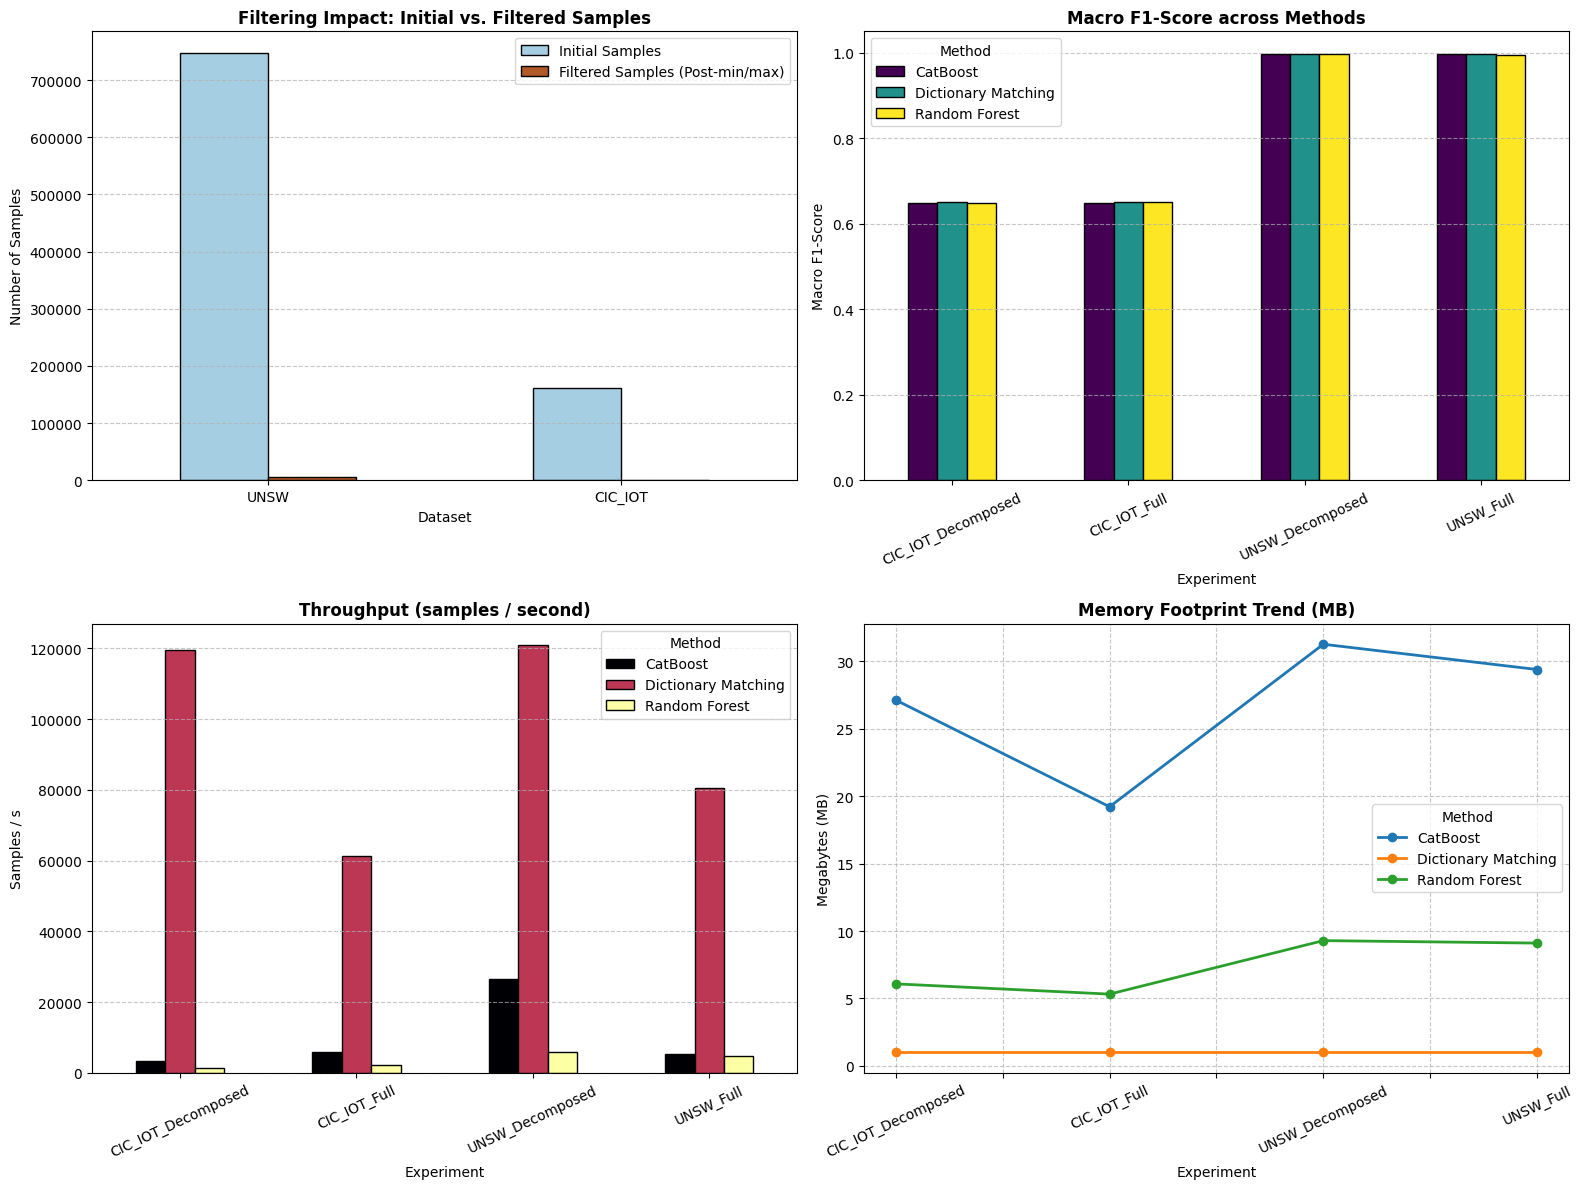

Advanced comparative plots saved to: C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\Resultados_Consolidados\Benchmark_Avanzado_Visualizacion.pdf


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Filtering Impact Bar Chart (Initial vs Filtered Samples)
df_audit.set_index("Dataset")[["Initial Samples", "Filtered Samples (Post-min/max)"]].plot(kind="bar", ax=axes[0, 0], colormap="Paired", edgecolor="black")
axes[0, 0].set_title("Filtering Impact: Initial vs. Filtered Samples", fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel("Number of Samples", fontsize=10)
axes[0, 0].grid(axis="y", linestyle="--", alpha=0.7)
axes[0, 0].tick_params(axis="x", rotation=0)

# 2. Macro F1-Score Comparison
pivot_f1 = df_summary.pivot(index="Experiment", columns="Method", values="F1-Score (Macro)")
pivot_f1.plot(kind="bar", ax=axes[0, 1], colormap="viridis", edgecolor="black")
axes[0, 1].set_title("Macro F1-Score across Methods", fontsize=12, fontweight='bold')
axes[0, 1].set_ylabel("Macro F1-Score", fontsize=10)
axes[0, 1].set_ylim(0, 1.05)
axes[0, 1].grid(axis="y", linestyle="--", alpha=0.7)
axes[0, 1].tick_params(axis="x", rotation=25)

# 3. Throughput (samples/s)
pivot_tp = df_summary.pivot(index="Experiment", columns="Method", values="Throughput (samples/s)")
pivot_tp.plot(kind="bar", ax=axes[1, 0], colormap="inferno", edgecolor="black")
axes[1, 0].set_title("Throughput (samples / second)", fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel("Samples / s", fontsize=10)
axes[1, 0].grid(axis="y", linestyle="--", alpha=0.7)
axes[1, 0].tick_params(axis="x", rotation=25)

# 4. Memory Footprint Trend
pivot_mem = df_summary.pivot(index="Experiment", columns="Method", values="Memory (MB)")
pivot_mem.plot(kind="line", marker='o', ax=axes[1, 1], linewidth=2)
axes[1, 1].set_title("Memory Footprint Trend (MB)", fontsize=12, fontweight='bold')
axes[1, 1].set_ylabel("Megabytes (MB)", fontsize=10)
axes[1, 1].grid(True, linestyle="--", alpha=0.7)
axes[1, 1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plot_path = os.path.join(OUTPUT_DIR, "Benchmark_Avanzado_Visualizacion.pdf")
plt.savefig(plot_path, format="pdf", bbox_inches="tight")
plt.show()
print(f"Advanced comparative plots saved to: {plot_path}")

### Individual Timing Figures

The following figures compare each method separately for training time, inference latency and throughput. The experiment labels distinguish datasets and Full versus Decomposed representations.

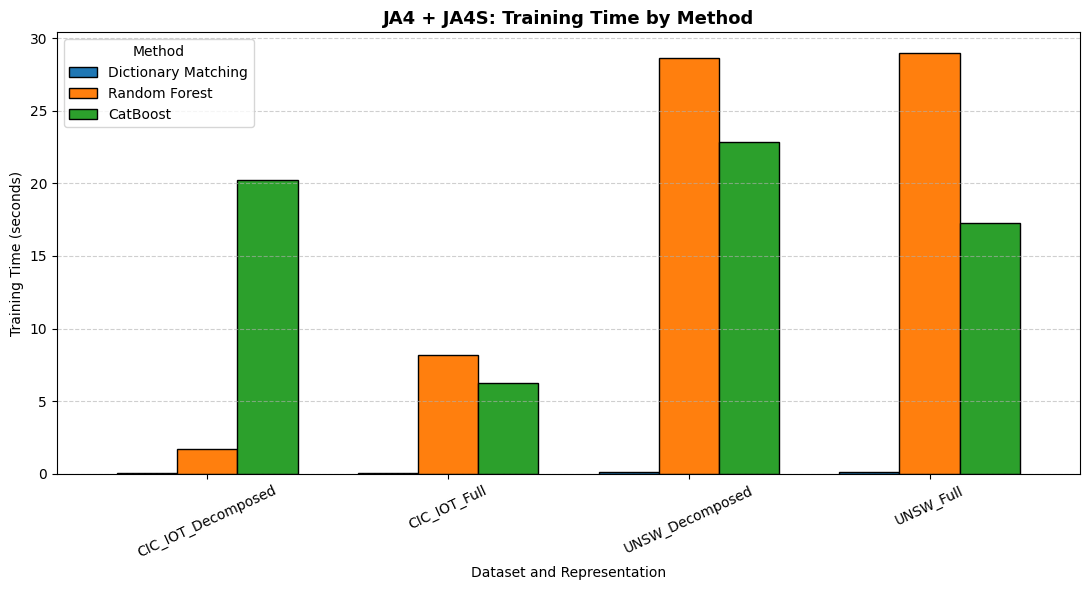

Saved: C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\Resultados_Consolidados\JA4_JA4S_training_time.pdf


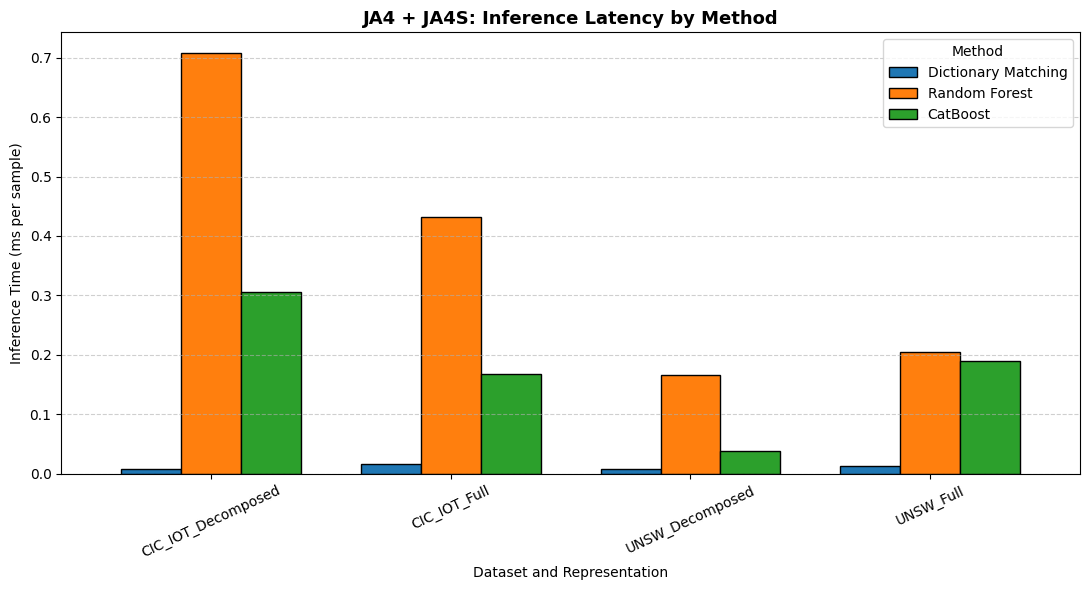

Saved: C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\Resultados_Consolidados\JA4_JA4S_inference_latency.pdf


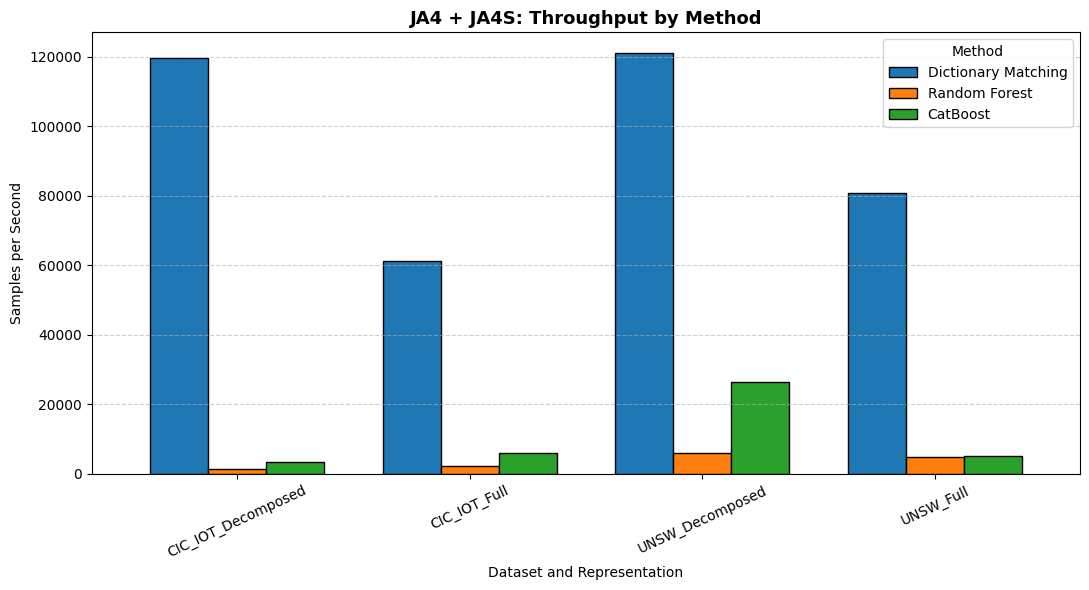

Saved: C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\Resultados_Consolidados\JA4_JA4S_throughput.pdf


In [ ]:
import os
import matplotlib.pyplot as plt
import pandas as pd

COMBINATION_LABEL = "JA4 + JA4S"
OUTPUT_TAG = "JA4_JA4S"
TIMING_OUTPUT_DIR = r"C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\Resultados_Consolidados"
os.makedirs(TIMING_OUTPUT_DIR, exist_ok=True)
timing_results = pd.DataFrame(all_global_results)
method_order = ["Dictionary Matching", "Random Forest", "CatBoost"]
timing_metrics = [
    ("Training Time (s)", "Training Time by Method", "Training Time (seconds)", "training_time"),
    ("Inference Time (ms/sample)", "Inference Latency by Method", "Inference Time (ms per sample)", "inference_latency"),
    ("Throughput (samples/s)", "Throughput by Method", "Samples per Second", "throughput")
]

# Re-run the benchmark definition and execution cells above if this fails after an edit.
missing_metrics = [metric for metric, *_ in timing_metrics if metric not in timing_results.columns]
if missing_metrics:
    raise KeyError(
        f"Missing columns in all_global_results: {missing_metrics}. "
        "Re-run the benchmark function cell and the dataset execution cell above, "
        "then re-run this cell."
    )

for metric, title, y_label, file_suffix in timing_metrics:
    timing_pivot = timing_results.pivot_table(
        index="Experiment", columns="Method", values=metric, aggfunc="mean"
    )
    timing_pivot = timing_pivot.reindex(columns=[method for method in method_order if method in timing_pivot.columns])
    ax = timing_pivot.plot(kind="bar", figsize=(11, 6), edgecolor="black", width=0.75)
    ax.set_title(f"{COMBINATION_LABEL}: {title}", fontsize=13, fontweight="bold")
    ax.set_xlabel("Dataset and Representation", fontsize=10)
    ax.set_ylabel(y_label, fontsize=10)
    ax.grid(axis="y", linestyle="--", alpha=0.6)
    ax.legend(title="Method")
    ax.tick_params(axis="x", rotation=25)
    plt.tight_layout()
    figure_path = os.path.join(TIMING_OUTPUT_DIR, f"{OUTPUT_TAG}_{file_suffix}.pdf")
    ax.figure.savefig(figure_path, format="pdf", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(ax.figure)
    print(f"Saved: {figure_path}")